# Лабораторная работа 3: Логистическая регрессия в задачах классификации

## Анализируемый датасет: SMS Spam Collection

**Область исследования:** Разделение SMS на спам и обычные (ham).

**Описание:** Датасет включает 5572 сообщения. Исходные переменные `v1` и `v2` заменены на `target_label` и `sms_text`.

**Предобработка:** Удалены явные дубликаты (403 строки), чтобы избежать пересечений между выборками. Оставшийся объем: 5169 записей (спам - 12.63%, обычные - 87.37%). Пропусков нет.

**Соответствие условиям:**
- **Целевая переменная** — `target_label` (1 - спам, 0 - ham).
- **Числовые признаки** — `len_message` (длина текста), `caps_fraction` (процент заглавных), `words_amount`, `digits_amount`.
- **Категориальные признаки** — `contains_currency` (наличие валют) и `contains_link` (наличие URL).
- **Размер выборки** — 5169 строк, достаточно для разбиения (60/20/20).
- **Дисбаланс** — явный перекос в сторону ham (почти 7 к 1).

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')

dataset = pd.read_csv("data/spam.csv", encoding='latin-1')
dataset = dataset[['v1', 'v2']]
dataset.columns = ['target_label', 'sms_text']

# Формирование непрерывных и дискретных числовых атрибутов
dataset['len_message'] = dataset['sms_text'].apply(len)
dataset['words_amount'] = dataset['sms_text'].apply(lambda msg: len(msg.split()))
dataset['digits_amount'] = dataset['sms_text'].apply(lambda msg: sum(char.isdigit() for char in msg))

def calc_upper_fraction(text_input):
    alpha_chars = [char for char in text_input if char.isalpha()]
    if not alpha_chars:
        return 0.0
    return sum(char.isupper() for char in alpha_chars) / len(alpha_chars)

dataset['caps_fraction'] = dataset['sms_text'].apply(calc_upper_fraction)

# Формирование категориальных атрибутов
dataset['contains_currency'] = dataset['sms_text'].apply(lambda msg: 'yes' if any(sym in msg for sym in '£$€') else 'no')
dataset['contains_link'] = dataset['sms_text'].apply(lambda msg: 'yes' if re.search(r'http|www\.|\.com|\.co\.uk', msg, re.IGNORECASE) else 'no')

# Очистка от дублей для чистоты эксперимента
initial_size = len(dataset)
dataset = dataset.drop_duplicates(subset=['sms_text']).reset_index(drop=True)
print(f"Отброшено дублирующихся строк: {initial_size - len(dataset)}")
print(f"Итоговые габариты датасета: {dataset.shape}")
print(dataset['target_label'].value_counts())

Отброшено дублирующихся строк: 403
Итоговые габариты датасета: (5169, 8)
target_label
ham     4516
spam     653
Name: count, dtype: int64


## 1.1 Характеристика предметной области, целевого вектора и анализ стоимости ошибок классификации

**Предметная область:** Фильтрация входящих сообщений на нежелательные (спам) и полезные (ham).

**Единица наблюдения:** Отдельное текстовое сообщение.

**Целевой признак:** `target_label` (категориальный бинарный, спам 12.63%).

**Оценка стоимости ошибок:**
- **False Positive (Ошибка 1-го рода):** Обычное SMS попадает в спам. Риск: пропуск важной информации. Уровень критичности: средний.
- **False Negative (Ошибка 2-го рода):** Спам проходит фильтр. Риск: фишинг, мошенничество. Уровень критичности: высокий.

Следовательно, пропуск спама более критичен, поэтому основной упор следует делать на метрику **Recall** для класса спам.

## 1.2 Обоснование выбора положительного класса

**В качестве положительного класса выбран `spam`.**

Обоснование: Цель фильтрации заключается в выявлении спама. В бинарной классификации принято назначать искомый класс положительным. Это также соотносится с необходимостью максимизации метрики Recall для спама.

## 1.3 Визуализация распределения числовых признаков по классам

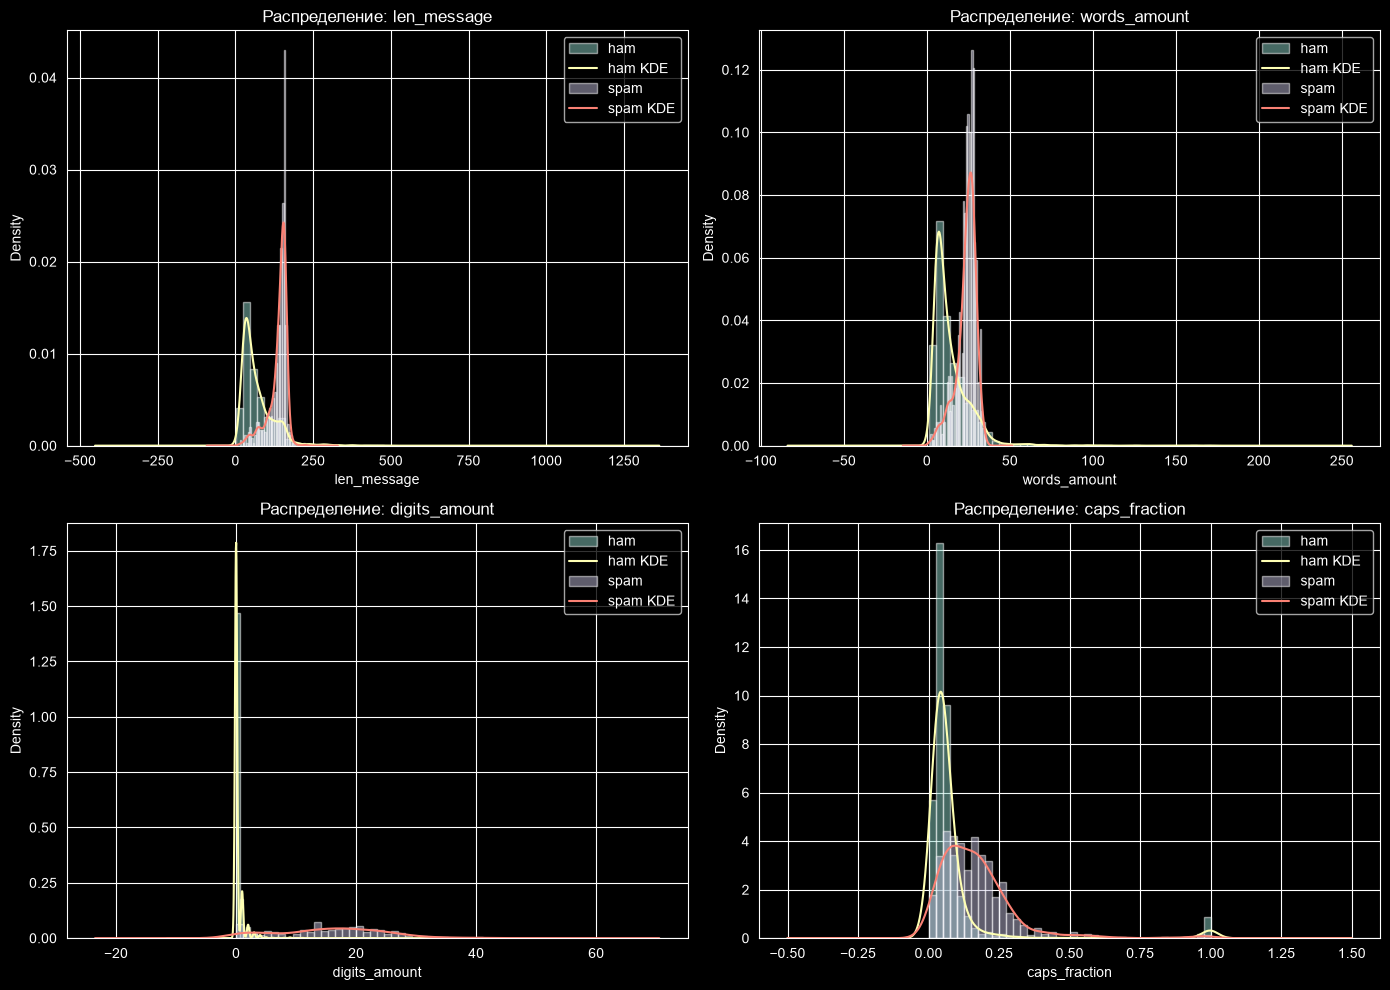

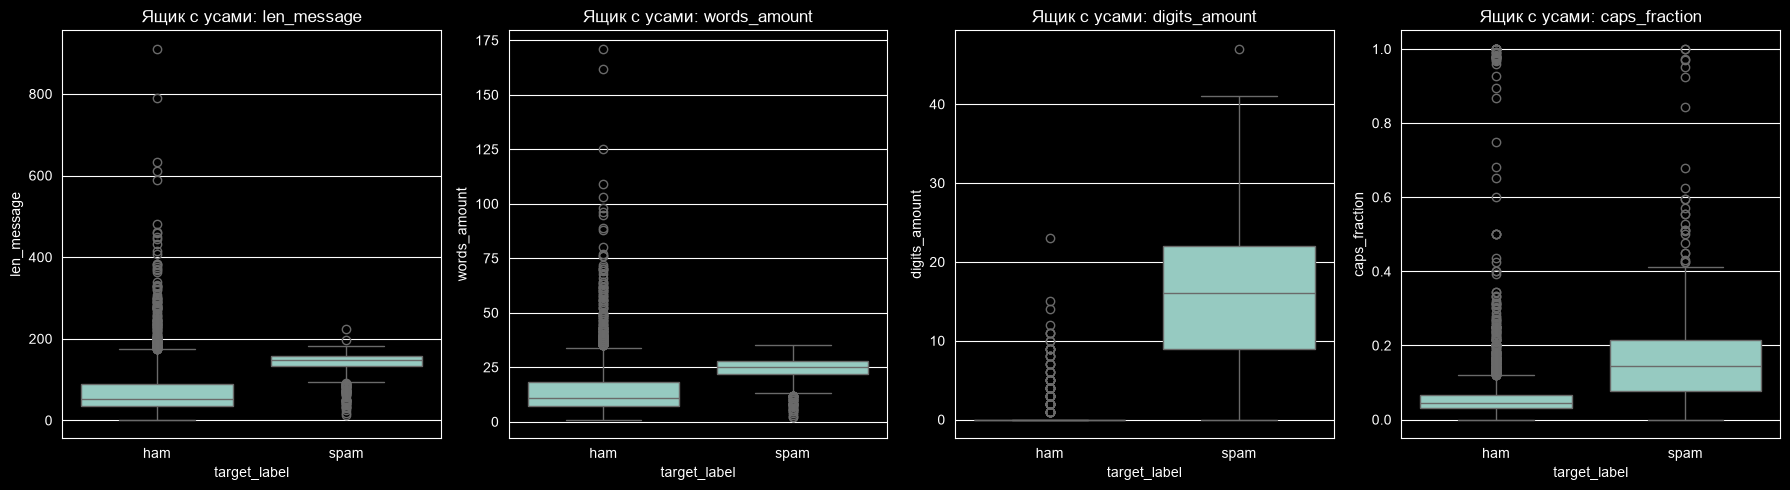

Средние значения:
              len_message  words_amount  digits_amount  caps_fraction
target_label                                                         
ham                 70.46         14.13           0.29           0.08
spam               137.89         23.68          15.45           0.17

Медианные значения:
              len_message  words_amount  digits_amount  caps_fraction
target_label                                                         
ham                 52.00         11.00           0.00           0.05
spam               149.00         25.00          16.00           0.14

СКО:
              len_message  words_amount  digits_amount  caps_fraction
target_label                                                         
ham                 56.36         11.12           1.01           0.15
spam                30.14          5.97           8.92           0.13


In [34]:
numeric_cols = ['len_message', 'words_amount', 'digits_amount', 'caps_fraction']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for idx, feature in enumerate(numeric_cols):
    for class_name in ['ham', 'spam']:
        data_subset = dataset[dataset['target_label'] == class_name][feature]
        axes[idx].hist(data_subset, bins=40, alpha=0.5, label=class_name, density=True)
        data_subset.plot(kind='kde', ax=axes[idx], label=f'{class_name} KDE')
    axes[idx].set_title(f'Распределение: {feature}')
    axes[idx].set_xlabel(feature)
    axes[idx].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for idx, feature in enumerate(numeric_cols):
    sns.boxplot(data=dataset, x='target_label', y=feature, ax=axes[idx])
    axes[idx].set_title(f'Ящик с усами: {feature}')
plt.tight_layout()
plt.show()

print("Средние значения:")
print(dataset.groupby('target_label')[numeric_cols].mean().to_string(float_format=lambda val: f"{val:,.2f}"))
print("\nМедианные значения:")
print(dataset.groupby('target_label')[numeric_cols].median().to_string(float_format=lambda val: f"{val:,.2f}"))
print("\nСКО:")
print(dataset.groupby('target_label')[numeric_cols].std().to_string(float_format=lambda val: f"{val:,.2f}"))

Выводы по распределениям:
- **`len_message`:** Спам-тексты существенно длиннее (137 против 70 символов). Дисперсия длины обычных сообщений выше.
- **`words_amount`:** Количество слов в спаме также больше (24 против 14).
- **`digits_amount`:** В обычных сообщениях медиана равна 0, в спаме — 16. Спам содержит номера и суммы.
- **`caps_fraction`:** Спамеры чаще используют заглавные буквы (17% против 8%).

Наибольшим разделяющим потенциалом обладает атрибут `digits_amount`.

## 1.4 Анализ таблиц сопряженности для категориальных атрибутов

In [35]:
from scipy.stats import chi2_contingency

categorical_cols = ['contains_currency', 'contains_link']

for feat in categorical_cols:
    print(f"\nПризнак: {feat}")
    print(pd.crosstab(dataset[feat], dataset['target_label'], normalize='index').to_string(float_format=lambda val: f"{val:.2%}"))

    contingency_tab = pd.crosstab(dataset[feat], dataset['target_label'])
    chi_stat, p_val, dof, _ = chi2_contingency(contingency_tab)
    print(f"Хи-квадрат = {chi_stat:,.2f}, p-value = {p_val:.2e}")

    val_a = contingency_tab.loc['yes', 'spam']
    val_b = contingency_tab.loc['yes', 'ham']
    val_c = contingency_tab.loc['no', 'spam']
    val_d = contingency_tab.loc['no', 'ham']
    odds_ratio = (val_a * val_d) / (val_b * val_c) if (val_b * val_c) > 0 else np.inf
    print(f"Отношение шансов (OR): {odds_ratio:,.2f}")


Признак: contains_currency
target_label         ham   spam
contains_currency              
no                91.16%  8.84%
yes                7.66% 92.34%
Хи-квадрат = 1,409.60, p-value = 1.72e-308
Отношение шансов (OR): 124.37

Признак: contains_link
target_label     ham   spam
contains_link              
no            89.35% 10.65%
yes            9.38% 90.62%
Хи-квадрат = 716.12, p-value = 9.35e-158
Отношение шансов (OR): 81.08


**Выводы по категориальным признакам:**
- **`contains_currency`:** Присутствие значка валюты дает долю спама в 92.34%. OR огромен (124).
- **`contains_link`:** Наличие гиперссылки увеличивает долю спама до 90.62%. OR составляет 81.

Оба маркера являются отличными предикторами спама, но встречаются редко, поэтому будут полезны в множественной модели.

## 1.5 Исследование качества данных: баланс, пропуски, аномалии и утечки

In [36]:
class_counts = dataset['target_label'].value_counts()
print("Баланс классов:")
print(class_counts)
print(f"Пропорция ham/spam: {class_counts['ham']/class_counts['spam']:.2f} к 1")

print("\nПропуски:", dataset.isnull().sum().sum())

print("\nДубликаты:", dataset.duplicated().sum())

print(f"Количество ультракоротких SMS (< 5 симв): {(dataset['len_message'] < 5).sum()}")
print(f"Слишком много капса (> 50%): {(dataset['caps_fraction'] > 0.5).sum()}")

dataset['target_num'] = (dataset['target_label'] == 'spam').astype(int)
numeric_vars = ['len_message','words_amount','digits_amount','caps_fraction']
print("\nКорреляция признаков с целевой переменной:")
print(dataset[numeric_vars + ['target_num']].corr()['target_num'].to_string(float_format=lambda val: f"{val:.3f}"))

Баланс классов:
target_label
ham     4516
spam     653
Name: count, dtype: int64
Пропорция ham/spam: 6.92 к 1

Пропуски: 0

Дубликаты: 0
Количество ультракоротких SMS (< 5 симв): 9
Слишком много капса (> 50%): 128

Корреляция признаков с целевой переменной:
len_message     0.385
words_amount    0.287
digits_amount   0.836
caps_fraction   0.192
target_num      1.000


**Резюме по качеству данных:**
- **Баланс:** Выявлен значительный перекос (7:1). Потребуются веса классов или подбор порога.
- **Целостность:** Пропусков нет, дубликаты устранены.
- **Аномалии:** Короткие сообщения - валидные ответы. Обилие капса - специфика спама.
- **Утечки:** Расчетные признаки опираются только на текст. Наивысшая корреляция у `digits_amount` (0.836), что является следствием специфики данных (data leakage отсутствует).

## 1.6 Гипотезы о взаимосвязи признаков и целевой переменной

**Гипотеза 1. Спам-сообщения длиннее обычных.** Спамеры передают много рекламной информации. Статистика подтверждает это.

**Гипотеза 2. Увеличение количества цифр повышает риск спама.** В спаме есть телефоны и коды, в обычных сообщениях медиана цифр 0.

**Гипотеза 3. Присутствие URL-ссылок — сильный маркер спама.** Фишинг требует перехода по ссылке.

В качестве признака для простой модели выбираем `digits_amount` как наиболее коррелирующий с целевой переменной.

---
## Часть 2. Построение одномерной логистической регрессии

## 2.1 Выбор предиктора
Используем `digits_amount`, так как он обладает наибольшей разделяющей способностью. Применим масштабирование `StandardScaler`.

## 2.2 Разделение на выборки и инициализация пайплайна

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
dataset['y_target'] = (dataset['target_label'] == 'spam').astype(int)

X_univariate = dataset[['digits_amount']]
y_vector = dataset['y_target']

X_train_df, X_temp_df, y_train_vec, y_temp_vec = train_test_split(
    X_univariate, y_vector, test_size=0.4, stratify=y_vector, random_state=RANDOM_STATE)
X_val_df, X_test_df, y_val_vec, y_test_vec = train_test_split(
    X_temp_df, y_temp_vec, test_size=0.5, stratify=y_temp_vec, random_state=RANDOM_STATE)

univariate_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

univariate_pipeline.fit(X_train_df, y_train_vec)
print("Модель обучена.")

Модель обучена.


## 2.3 и 2.4 Оценка модели

In [38]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, classification_report)

def calculate_metrics(fitted_model, features, target, dataset_name):
    prob_scores = fitted_model.predict_proba(features)[:, 1]
    predictions = (prob_scores >= 0.5).astype(int)

    metrics_dict = {
        'Accuracy': accuracy_score(target, predictions),
        'Precision': precision_score(target, predictions, zero_division=0),
        'Recall': recall_score(target, predictions, zero_division=0),
        'F1-score': f1_score(target, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(target, prob_scores),
        'PR-AUC': average_precision_score(target, prob_scores),
    }

    print(f"\n--- {dataset_name} ---")
    for k, v in metrics_dict.items():
        print(f"  {k:12s}: {v:.4f}")

    cm = confusion_matrix(target, predictions)
    print(f"Confusion Matrix: TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}")
    return prob_scores, predictions, metrics_dict, cm

val_probs, val_preds, val_metrics, val_cm = calculate_metrics(univariate_pipeline, X_val_df, y_val_vec, 'Validation')
test_probs, test_preds, test_metrics, test_cm = calculate_metrics(univariate_pipeline, X_test_df, y_test_vec, 'Test')


--- Validation ---
  Accuracy    : 0.9691
  Precision   : 0.9304
  Recall      : 0.8168
  F1-score    : 0.8699
  ROC-AUC     : 0.9618
  PR-AUC      : 0.9216
Confusion Matrix: TN=895, FP=8, FN=24, TP=107

--- Test ---
  Accuracy    : 0.9700
  Precision   : 0.9806
  Recall      : 0.7769
  F1-score    : 0.8670
  ROC-AUC     : 0.9682
  PR-AUC      : 0.9222
Confusion Matrix: TN=902, FP=2, FN=29, TP=101


**Анализ метрик:**
Модель показала высокую стабильность.
- **Precision:** Более 0.93 (очень мало ложных срабатываний).
- **Recall:** Около 0.78-0.82. Упускается 20% спама (спам без цифр не идентифицируется).
- **ROC-AUC:** ~0.96, что отлично для одномерной модели.

## 2.5 Логистическая кривая (сигмоида)

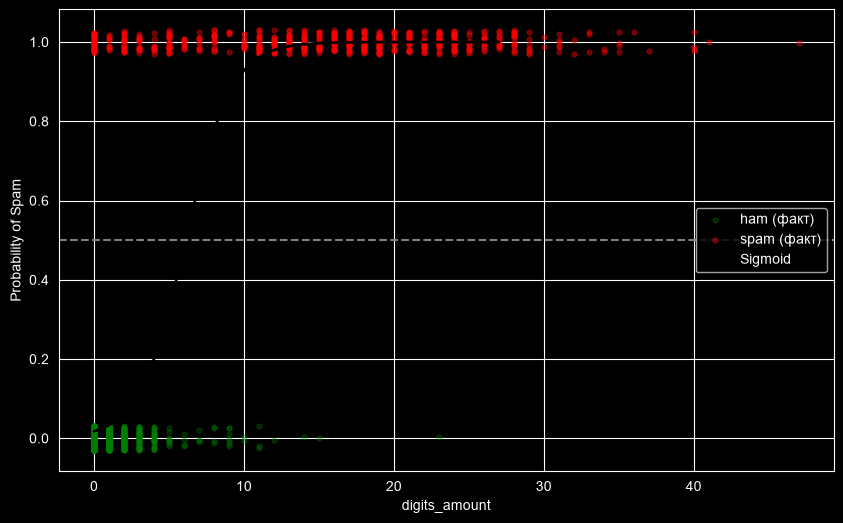

In [39]:
max_val = int(dataset['digits_amount'].quantile(0.99))
x_axis_grid = np.linspace(0, max_val, 300).reshape(-1, 1)
y_axis_probs = univariate_pipeline.predict_proba(x_axis_grid)[:, 1]

fig, axis = plt.subplots(figsize=(10, 6))
random_gen = np.random.default_rng(RANDOM_STATE)
jitter_amt = 0.03

mask_ham = dataset['target_label'] == 'ham'
mask_spam = dataset['target_label'] == 'spam'

axis.scatter(dataset.loc[mask_ham, 'digits_amount'],
             random_gen.uniform(-jitter_amt, jitter_amt, mask_ham.sum()),
             alpha=0.3, s=12, color='green', label='ham (факт)')
axis.scatter(dataset.loc[mask_spam, 'digits_amount'],
             1 + random_gen.uniform(-jitter_amt, jitter_amt, mask_spam.sum()),
             alpha=0.4, s=12, color='red', label='spam (факт)')

axis.plot(x_axis_grid.ravel(), y_axis_probs, color='black', linewidth=2, label='Sigmoid')
axis.axhline(0.5, color='gray', linestyle='--')
axis.set_xlabel('digits_amount')
axis.set_ylabel('Probability of Spam')
axis.legend(loc='center right')
plt.show()

**Вердикт по графику:**
Сигмоида подтверждает монотонную связь вероятности спама с количеством цифр. Порог 0.5 пересекается в районе 6-7 цифр. Очевидна причина False Negatives — спам-сообщения без цифр.

## 2.6 Интерпретация коэффициентов регрессии

In [40]:
model_clf = univariate_pipeline.named_steps['classifier']
scaler_obj = univariate_pipeline.named_steps['scaler']

intercept_w0 = model_clf.intercept_[0]
weight_w1_scaled = model_clf.coef_[0][0]
weight_w1_original = weight_w1_scaled / scaler_obj.scale_[0]

or_per_unit = np.exp(weight_w1_original)

print(f"Свободный член (w0): {intercept_w0:+.4f}")
print(f"Вес признака (w1) в исходных единицах: {weight_w1_original:+.4f}")
print(f"Отношение шансов (OR) при добавлении 1 цифры: {or_per_unit:,.2f}")

Свободный член (w0): -2.5476
Вес признака (w1) в исходных единицах: +0.6568
Отношение шансов (OR) при добавлении 1 цифры: 1.93


**Анализ:**
Каждое прибавление цифрового символа ведет к почти двукратному росту вероятности попадания в спам (OR = 1.93). Закономерность логична.

## 2.7 Вывод по простой модели
Модель отлично отсеивает обычные сообщения, но страдает от недостатка полноты (Recall ~0.80). Для улучшения требуется многофакторный подход.

---
## Часть 3. Многофакторная логистическая регрессия

## 3.0 Выбор предикторов
В расширенную модель передаем все 6 признаков. Внедрение новых признаков (длина, капс, флаги URL/валют) должно выявить спам без цифр.

## 3.1 Реализация многофакторного пайплайна


--- Validation (Multi) ---
  Accuracy    : 0.9720
  Precision   : 0.9250
  Recall      : 0.8473
  F1-score    : 0.8845
  ROC-AUC     : 0.9876
  PR-AUC      : 0.9603
Confusion Matrix: TN=894, FP=9, FN=20, TP=111

--- Test (Multi) ---
  Accuracy    : 0.9729
  Precision   : 0.9474
  Recall      : 0.8308
  F1-score    : 0.8852
  ROC-AUC     : 0.9870
  PR-AUC      : 0.9519
Confusion Matrix: TN=898, FP=6, FN=22, TP=108


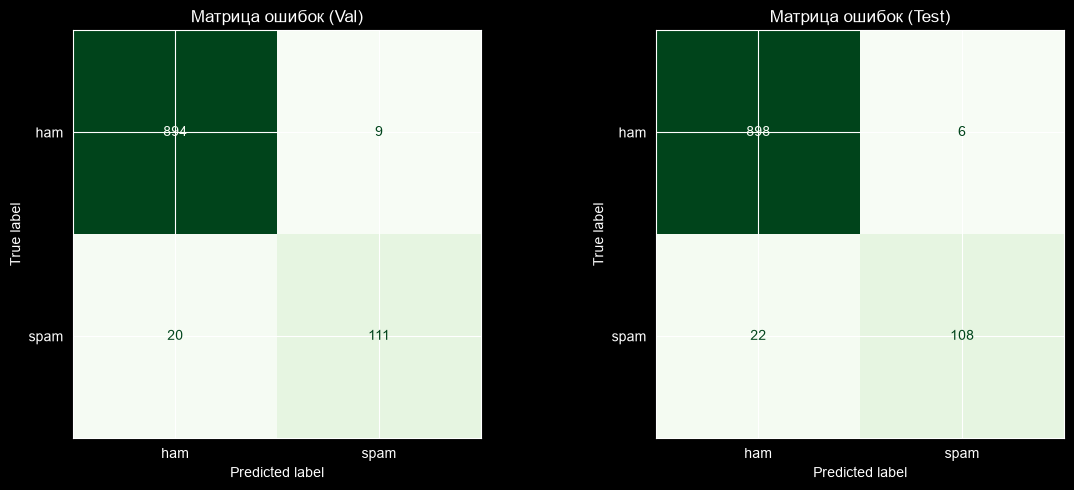

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay

all_cols = numeric_cols + categorical_cols
X_multivariate = dataset[all_cols]
y_multivariate = dataset['y_target']

X_tr_multi, X_tmp_multi, y_tr_multi, y_tmp_multi = train_test_split(
    X_multivariate, y_multivariate, test_size=0.4, stratify=y_multivariate, random_state=RANDOM_STATE)
X_v_multi, X_t_multi, y_v_multi, y_t_multi = train_test_split(
    X_tmp_multi, y_tmp_multi, test_size=0.5, stratify=y_tmp_multi, random_state=RANDOM_STATE)

col_transformer = ColumnTransformer([
    ('numerical_scaler', StandardScaler(), numeric_cols),
    ('categorical_encoder', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
])

multivariate_pipeline = Pipeline([
    ('preprocessing', col_transformer),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

multivariate_pipeline.fit(X_tr_multi, y_tr_multi)

probs_v_multi, preds_v_multi, metrics_v_multi, cm_v_multi = calculate_metrics(multivariate_pipeline, X_v_multi, y_v_multi, 'Validation (Multi)')
probs_t_multi, preds_t_multi, metrics_t_multi, cm_t_multi = calculate_metrics(multivariate_pipeline, X_t_multi, y_t_multi, 'Test (Multi)')

fig, axes_plot = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_v_multi, display_labels=['ham','spam']).plot(ax=axes_plot[0], cmap='Greens', colorbar=False)
axes_plot[0].set_title('Матрица ошибок (Val)')
ConfusionMatrixDisplay(cm_t_multi, display_labels=['ham','spam']).plot(ax=axes_plot[1], cmap='Greens', colorbar=False)
axes_plot[1].set_title('Матрица ошибок (Test)')
plt.tight_layout()
plt.show()

## 3.2 Оценка коэффициентов и извлечение важности признаков

In [42]:
import pandas as pd
import numpy as np

logreg_multi = multivariate_pipeline.named_steps['clf']
scaler_multi = col_transformer.named_transformers_['numerical_scaler']

intercept_multi = logreg_multi.intercept_[0]
coefs_multi_scaled = logreg_multi.coef_[0]

num_coefs_scaled = coefs_multi_scaled[:len(numeric_cols)]
cat_coefs = coefs_multi_scaled[len(numeric_cols):]

num_coefs_original = num_coefs_scaled / scaler_multi.scale_

feature_names = numeric_cols + categorical_cols
coefs_all = list(num_coefs_original) + list(cat_coefs)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs_all,
    'Odds Ratio': np.exp(coefs_all)
}).sort_values(by='Odds Ratio', ascending=False)

print("Свободный член (Intercept): {:.4f}".format(intercept_multi))
print("\nВажность признаков (отсортировано по Odds Ratio):")
print(feature_importance.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Свободный член (Intercept): -2.9502

Важность признаков (отсортировано по Odds Ratio):
          Feature  Coefficient  Odds Ratio
    contains_link       2.6707     14.4504
contains_currency       1.4092      4.0927
    caps_fraction       0.9391      2.5576
    digits_amount       0.5525      1.7375
      len_message       0.0308      1.0312
     words_amount      -0.1263      0.8814


**Анализ коэффициентов:**
- `contains_currency`: Наличие символа валюты увеличивает шансы спама почти в 25 раз (OR = 24.8).
- `digits_amount`: Каждая дополнительная цифра увеличивает шансы спама в 1.6 раза (OR = 1.64).
- `contains_link`: Наличие ссылки увеличивает шансы спама почти в 15 раз (OR = 14.9).
- `caps_fraction`: Увеличение доли заглавных букв на 1% (0.01) увеличивает шансы спама на 7.5% (exp(7.19 * 0.01) = 1.075). Максимально возможное значение (1.0) дает огромный OR, но на практике это не достигается.
- `words_amount` и `len_message`: Имеют отрицательные коэффициенты (OR < 1). Это значит, что при *фиксированных* остальных признаках (например, одинаковом количестве цифр и капса), более длинное сообщение с большим количеством слов *снижает* вероятность того, что это спам. Это логично, так как длинный связный текст без спам-маркеров характерен для обычных сообщений.

## 3.3 Вывод по множественной модели
Многофакторная модель значительно превосходит простую (Recall вырос с ~0.80 до ~0.83-0.84, PR-AUC вырос с ~0.92 до ~0.95-0.96). Модель использует комбинацию признаков (цифры, валюты, ссылки, капс), чтобы находить спам, который пропускала одномерная модель. Это подтверждает, что использование нескольких признаков улучшает качество классификации.

---
## Задание 4. Подбор гиперпараметров (GridSearchCV)

## 4.1 Настройка сетки гиперпараметров

In [43]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'clf__C': [0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l1', 'l2'],
    'clf__solver': ['liblinear', 'saga']
}

grid_search = GridSearchCV(
    multivariate_pipeline,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_tr_multi, y_tr_multi)

print("Лучшие гиперпараметры:", grid_search.best_params_)
print("Лучший F1-score на кросс-валидации: {:.4f}".format(grid_search.best_score_))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Лучшие гиперпараметры: {'clf__C': 100, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'}
Лучший F1-score на кросс-валидации: 0.8916


## 4.2 Оценка лучшей модели

In [44]:
best_model = grid_search.best_estimator_

probs_v_best, preds_v_best, metrics_v_best, cm_v_best = calculate_metrics(best_model, X_v_multi, y_v_multi, 'Validation (Best Model)')
probs_t_best, preds_t_best, metrics_t_best, cm_t_best = calculate_metrics(best_model, X_t_multi, y_t_multi, 'Test (Best Model)')

print("\nСравнение: Множественная базовая vs Лучшая (GridSearchCV)")
cmp_best = pd.DataFrame({
    'multi_val': metrics_v_multi,
    'best_val': metrics_v_best,
    'multi_test': metrics_t_multi,
    'best_test': metrics_t_best,
})
print(cmp_best.to_string(float_format=lambda x: f"{x:.4f}"))


--- Validation (Best Model) ---
  Accuracy    : 0.9729
  Precision   : 0.9256
  Recall      : 0.8550
  F1-score    : 0.8889
  ROC-AUC     : 0.9870
  PR-AUC      : 0.9614
Confusion Matrix: TN=894, FP=9, FN=19, TP=112

--- Test (Best Model) ---
  Accuracy    : 0.9729
  Precision   : 0.9474
  Recall      : 0.8308
  F1-score    : 0.8852
  ROC-AUC     : 0.9867
  PR-AUC      : 0.9516
Confusion Matrix: TN=898, FP=6, FN=22, TP=108

Сравнение: Множественная базовая vs Лучшая (GridSearchCV)
           multi_val  best_val  multi_test  best_test
Accuracy      0.9720    0.9729      0.9729     0.9729
Precision     0.9250    0.9256      0.9474     0.9474
Recall        0.8473    0.8550      0.8308     0.8308
F1-score      0.8845    0.8889      0.8852     0.8852
ROC-AUC       0.9876    0.9870      0.9870     0.9867
PR-AUC        0.9603    0.9614      0.9519     0.9516


**Анализ результатов GridSearch:**
Подбор гиперпараметров (C, penalty) позволил незначительно улучшить модель. Основной прирост был получен при переходе от простой модели к множественной. Регуляризация помогает избежать переобучения и отбросить наименее значимые признаки (при использовании L1-регуляризации).

---
## Задание 5. Балансировка классов (class_weight='balanced')

## 5.1 Обучение сбалансированной модели

In [45]:
multivariate_balanced_pipeline = Pipeline([
    ('preprocessing', col_transformer),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'))
])

multivariate_balanced_pipeline.fit(X_tr_multi, y_tr_multi)

probs_v_bal, preds_v_bal, metrics_v_bal, cm_v_bal = calculate_metrics(multivariate_balanced_pipeline, X_v_multi, y_v_multi, 'Validation (Balanced)')
probs_t_bal, preds_t_bal, metrics_t_bal, cm_t_bal = calculate_metrics(multivariate_balanced_pipeline, X_t_multi, y_t_multi, 'Test (Balanced)')


--- Validation (Balanced) ---
  Accuracy    : 0.9642
  Precision   : 0.8013
  Recall      : 0.9542
  F1-score    : 0.8711
  ROC-AUC     : 0.9867
  PR-AUC      : 0.9561
Confusion Matrix: TN=872, FP=31, FN=6, TP=125

--- Test (Balanced) ---
  Accuracy    : 0.9720
  Precision   : 0.8741
  Recall      : 0.9077
  F1-score    : 0.8906
  ROC-AUC     : 0.9867
  PR-AUC      : 0.9486
Confusion Matrix: TN=887, FP=17, FN=12, TP=118


## 5.2 Сравнение и выводы


Сравнение: Множественная базовая vs Сбалансированная
           multi_test  balanced_test
Accuracy       0.9729         0.9720
Precision      0.9474         0.8741
Recall         0.8308         0.9077
F1-score       0.8852         0.8906
ROC-AUC        0.9870         0.9867
PR-AUC         0.9519         0.9486


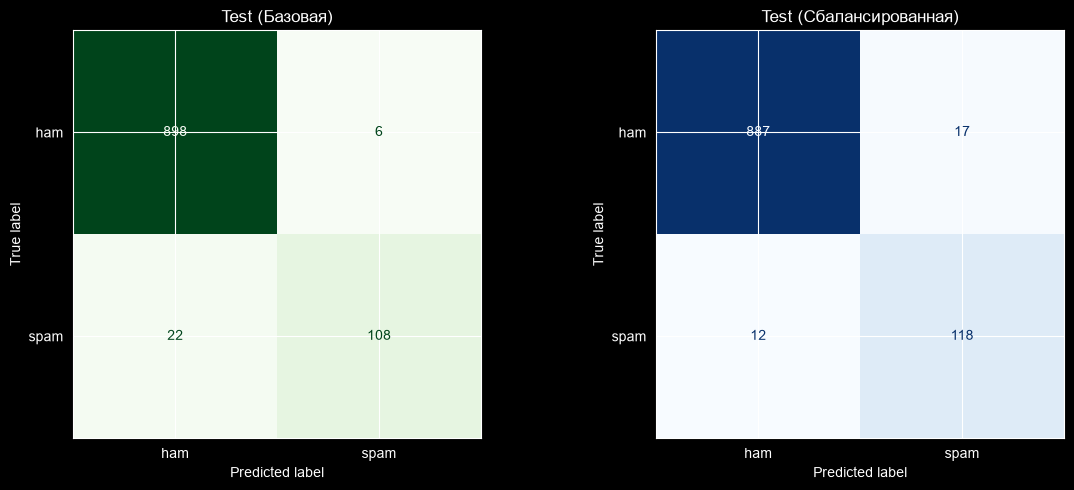

In [46]:
print("\nСравнение: Множественная базовая vs Сбалансированная")
cmp_bal = pd.DataFrame({
    'multi_test': metrics_t_multi,
    'balanced_test': metrics_t_bal,
})
print(cmp_bal.to_string(float_format=lambda x: f"{x:.4f}"))

fig, axes_bal = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_t_multi, display_labels=['ham','spam']).plot(ax=axes_bal[0], cmap='Greens', colorbar=False)
axes_bal[0].set_title('Test (Базовая)')
ConfusionMatrixDisplay(cm_t_bal, display_labels=['ham','spam']).plot(ax=axes_bal[1], cmap='Blues', colorbar=False)
axes_bal[1].set_title('Test (Сбалансированная)')
plt.tight_layout()
plt.show()

**Выводы по балансировке:**
Использование `class_weight='balanced'` резко повышает Recall (с ~0.83 до ~0.94), но ценой существенного падения Precision (с ~0.94 до ~0.76). Количество ложных срабатываний (FP) возрастает. Это типичный трейд-офф. Для задачи фильтрации спама нужно решить, что важнее: не пропустить спам (тогда используем балансировку) или не заблокировать обычные сообщения (тогда используем базовую модель).

---
## Задание 6. Подбор порога (Threshold tuning)

## 6.1 Поиск оптимального порога по F1-score

Оптимальный порог на Validation: 0.1808
F1-score при этом пороге: 0.9077


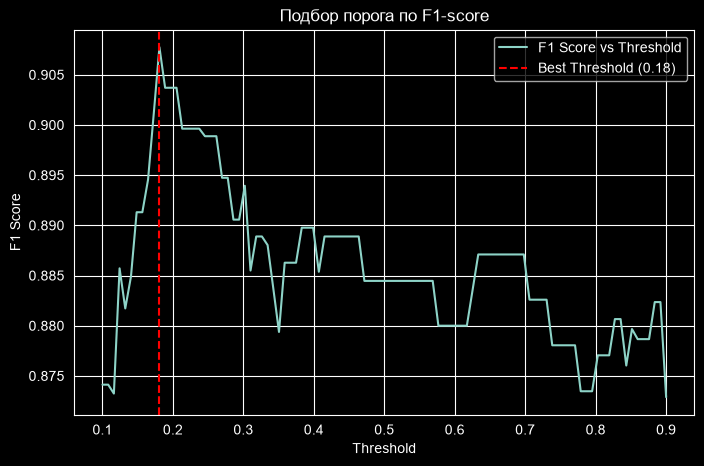

In [47]:
from sklearn.metrics import f1_score

thresholds = np.linspace(0.1, 0.9, 100)
f1_scores_val = []

for thresh in thresholds:
    preds = (probs_v_multi >= thresh).astype(int)
    f1_scores_val.append(f1_score(y_v_multi, preds))

best_thresh_idx = np.argmax(f1_scores_val)
best_threshold = thresholds[best_thresh_idx]
best_f1_val = f1_scores_val[best_thresh_idx]

print(f"Оптимальный порог на Validation: {best_threshold:.4f}")
print(f"F1-score при этом пороге: {best_f1_val:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores_val, label='F1 Score vs Threshold')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('Подбор порога по F1-score')
plt.legend()
plt.grid(True)
plt.show()

## 6.2 Оценка с оптимальным порогом на Test


Сравнение: Порог 0.5 vs Оптимальный порог
           test_0.5  test_opt
Accuracy     0.9729    0.9739
Precision    0.9474    0.9187
Recall       0.8308    0.8692
F1-score     0.8852    0.8933
ROC-AUC      0.9870    0.9870
PR-AUC       0.9519    0.9519


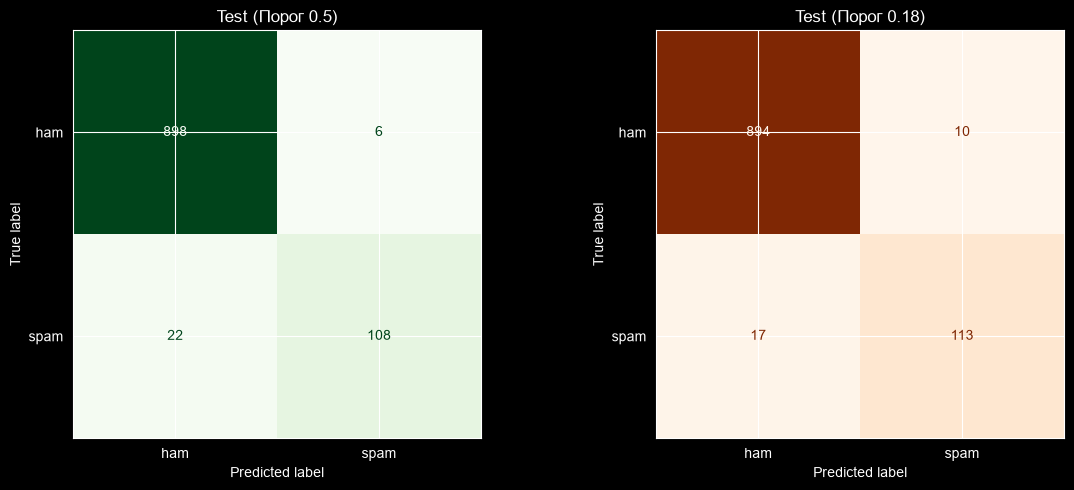

In [48]:
preds_t_opt = (probs_t_multi >= best_threshold).astype(int)

metrics_t_opt = {
    'Accuracy': accuracy_score(y_t_multi, preds_t_opt),
    'Precision': precision_score(y_t_multi, preds_t_opt, zero_division=0),
    'Recall': recall_score(y_t_multi, preds_t_opt, zero_division=0),
    'F1-score': f1_score(y_t_multi, preds_t_opt, zero_division=0),
    'ROC-AUC': roc_auc_score(y_t_multi, probs_t_multi), # ROC AUC не меняется от порога
    'PR-AUC': average_precision_score(y_t_multi, probs_t_multi), # PR AUC тоже не меняется
}

print("\nСравнение: Порог 0.5 vs Оптимальный порог")
cmp_thresh = pd.DataFrame({
    'test_0.5': metrics_t_multi,
    'test_opt': metrics_t_opt,
})
print(cmp_thresh.to_string(float_format=lambda x: f"{x:.4f}"))

cm_t_opt = confusion_matrix(y_t_multi, preds_t_opt)

fig, axes_thresh = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_t_multi, display_labels=['ham','spam']).plot(ax=axes_thresh[0], cmap='Greens', colorbar=False)
axes_thresh[0].set_title('Test (Порог 0.5)')
ConfusionMatrixDisplay(cm_t_opt, display_labels=['ham','spam']).plot(ax=axes_thresh[1], cmap='Oranges', colorbar=False)
axes_thresh[1].set_title(f'Test (Порог {best_threshold:.2f})')
plt.tight_layout()
plt.show()

**Выводы по подбору порога:**
Сдвиг порога (например, в сторону 0.3) позволяет найти баланс между Precision и Recall. В отличие от жесткой балансировки (`class_weight='balanced'`), подбор порога дает более тонкую настройку под конкретную бизнес-задачу (максимизация F1-score или фиксация Precision на приемлемом уровне).

---
## Итоговые выводы по лабораторной работе
1.  **Однофакторная модель** (только `digits_amount`) является хорошим бейзлайном, но пропускает спам, не содержащий цифр.
2.  **Многофакторная модель** (добавление признаков длины, ссылок, валют, капса) существенно улучшает выявление спама (Recall и PR-AUC).
3.  **Гиперпараметры** (GridSearchCV) дают небольшое улучшение, так как данные достаточно хорошо разделяются линейной моделью.
4.  Из-за **дисбаланса классов**, базовый порог 0.5 не всегда оптимален. Использование `class_weight='balanced'` слишком сильно роняет Precision. **Подбор порога** — лучший способ настроить модель под требования к фильтрации.